# PS week: simulated profile vs. Neware test results

Compares the simulated cell-level peak-shaving (PS) profile from `DEV_demo_PS.ipynb`
(current, voltage, SOC of the OCV+R0 model) with what the tester actually
recorded when running `output/generated_cell_profile_PS.txt` (49.9 h, filtered
week #28 of `PS_Cluster3.csv`).

- Measured data: the PS-week workbooks in `testresults/` (`TEST_RESULTS_GLOB`,
  test 2818580854 on ch 2-5 and 2-6, 4-6 Nov 2026), sheet `record`, rows of
  the `SIM` step only. The preconditioning before it (CCCV charge to 4.2 V,
  CC discharge of 2.07 Ah -> ~55 % SOC, rests) and the rest after it are not
  part of the comparison; the preconditioning is only read to know at which
  SOC the cell entered the SIM step.
- All currents are shown in the tester's convention: **positive = charge**.
- See the **Findings** section at the end for the summary, including the
  failed first attempt (test 2818580853) and the power outage during this run.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path

# Repo root (holds the toolchain modules and data), whether the kernel starts in
# comparison/ or in the root itself
MODULE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "profile_generation.py").exists())
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from select_representative_window import select_representative_window
from filter_profile import filter_profile
from cell_model_io import load_cell_model_xlsx, make_sim_cell_model
from profile_generation import run_battery_model
from _pg_helpers import apply_default_options, apply_default_datasheet

plt.rcParams["figure.dpi"] = 110

DATA_PATH = MODULE_DIR / "sample_data/PS_Cluster3.csv"
CELL_MODEL_PATH = MODULE_DIR / "sample_data/LGM50LT_A.xlsx"
NEWARE_PROFILE_PATH = MODULE_DIR / "output/generated_cell_profile_PS.txt"
TEST_RESULTS_DIR = MODULE_DIR / "testresults"
TEST_RESULTS_GLOB = "*-2818580854*.xlsx"  # completed PS-week run only (ch 2-5 and 2-6)

# Already-tuned best values from DEV_demo_PS.ipynb, so we just re-run the
# single best combination instead of the grid search.
SCALE_DIVISOR = 5500
DRIFT_CORRECTION = 0.90
ACTIVE_WEEKS = (24, 32)  # same active-season week range as DEV_demo_PS.ipynb
ETA_COULOMB = 0.99

# SOC (%) at which the cells entered the SIM step. None -> taken from the test
# itself (see load_sim_step): if the last pre-SIM step is a discharge after a
# CCCV charge, 100 % minus the Ah discharged; if it is a charge, the Ah charged
# counted from empty.
SOC_START_TEST = None

# Tester safety limits of the run (sheet 'test')
V_UPPER_LIMIT = 4.21
V_LOWER_LIMIT = 2.49

## 1. Simulated profile

Same selection / filter / model settings as `DEV_demo_PS.ipynb`. The
regenerated current is checked against the exported Neware file, so the
simulation below is guaranteed to be the profile that ran on the tester.

In [2]:
df = pd.read_csv(DATA_PATH)
power = df["power_W"].to_numpy()
soc = df["soc_pct"].to_numpy()
dt = int(df["time_s"].iloc[1] - df["time_s"].iloc[0])

WEEK = 7 * 24 * 3600 // dt
first_week, last_week = ACTIVE_WEEKS
sel = slice((first_week - 1) * WEEK, last_week * WEEK)

win = select_representative_window(
    power[sel], dt=dt, window_sec=7 * 24 * 3600, soc=soc[sel],
    metrics=["PosWh", "RT", "Nswap", "Eswap"],
)
filt = filter_profile(
    win.best_window_power, soc=win.best_window_soc,
    filter_rest_threshold=5.0, dt=dt, keep_rest_sec=300,
)

dsoc = np.diff(filt.soc_f)
p = filt.power_f[:-1]
charging_positive = p[dsoc > 0].mean() > 0

cm = load_cell_model_xlsx(CELL_MODEL_PATH)
sim_model = make_sim_cell_model(cm)
datasheet = apply_default_datasheet(cm.datasheet)

profile_data = {"power": filt.power_f, "soc": filt.soc_f}
opts = apply_default_options({
    "dt": dt,
    "scale_divisor": SCALE_DIVISOR,
    "drift_correction": DRIFT_CORRECTION,
    "use_current_limit": True,
    "eta_coulomb_ef": ETA_COULOMB,
    "charging_positive": charging_positive,
})

best = run_battery_model(profile_data, "power_soc", sim_model, datasheet, opts)
assert best.is_valid, best.message

# Tester convention: positive current is charge
sim_current = best.current if charging_positive else -best.current
n = sim_current.size

# The Neware file has one extra trailing 0 A row that the tester does not execute
neware = np.loadtxt(NEWARE_PROFILE_PATH)
assert neware.shape[0] == n + 1, "exported profile length differs from the simulation"
assert np.allclose(neware[:-1, 0], dt), "exported hold times differ from dt"
max_dev = np.max(np.abs(neware[:-1, 1] - sim_current))
assert max_dev < 1e-9, f"exported profile differs from the simulation (max {max_dev:.3g} A)"

print(f"Selected week #{first_week + win.idx_best} of the year")
print(f"Simulated profile: {n:,} rows @ dt={dt}s ({n * dt / 3600:.1f} h), "
      f"matches {NEWARE_PROFILE_PATH}")
print(f"simulated start SOC: {best.soc[0]:.1f} %, model capacity: {cm.capacity_Ah} Ah")

Selected week #28 of the year
Simulated profile: 179,674 rows @ dt=1s (49.9 h), matches /Users/tomasdolezal/Documents/Baterky/Projects/TestProfiles/BatteryTestProfileGeneration/output/generated_cell_profile_PS.txt
simulated start SOC: 61.5 %, model capacity: 4.589 Ah


## 2. Test results (`record` sheet, `SIM` step only)

The SIM step is logged every 10 s while the profile changes every second, so
each measured sample is compared with the simulated row that was being
executed at that instant: a sample at step time `t` falls at the end of
profile row `t/dt` (1-based).

In [3]:
def load_sim_step(path):
    """Returns the SIM-step rows of a Neware export (time / V / I / net Ah / T),
    the SOC (%) the cell entered the SIM step with, and how that was derived."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # openpyxl: "Workbook contains no default style"
        rec = pd.read_excel(path, sheet_name="record")
    sim = rec[rec["Step Type"] == "SIM"]
    if sim.empty:
        raise ValueError(f"{path}: no SIM step in sheet 'record'")
    if sim["Step ID"].nunique() != 1:
        raise ValueError(f"{path}: more than one SIM step, pick one explicitly")

    # Last charge or discharge step before SIM (rests are skipped). The record
    # "Capacity" column counts up from 0 within each step, for both directions.
    before = rec.loc[: sim.index[0] - 1]
    steps = before[before["Step Type"] != "Rest"].groupby("Step ID", sort=True) \
        .agg(step_type=("Step Type", "first"), Ah=("Capacity(Ah)(Ah)", "last"))
    soc0, how = np.nan, "no charge/discharge step before SIM"
    if not steps.empty:
        last = steps.iloc[-1]
        prev = steps.iloc[-2] if len(steps) > 1 else None
        if "DChg" in last.step_type and prev is not None and prev.step_type == "CCCV Chg":
            # full CCCV charge, then a set discharge -> counted down from 100 %
            soc0 = 100 - last.Ah / cm.capacity_Ah * 100
            how = f"CCCV charged to full, then discharged {last.Ah:.3f} Ah"
        elif "Chg" in last.step_type and "DChg" not in last.step_type:
            # emptied, then a set charge -> counted up from 0 %
            soc0 = last.Ah / cm.capacity_Ah * 100
            how = f"recharged {last.Ah:.3f} Ah from empty"

    meas = pd.DataFrame({
        "t_s": pd.to_timedelta(sim["Step Time"]).dt.total_seconds().to_numpy(),
        "voltage_V": sim["Voltage(V)(V)"].to_numpy(),
        "current_A": sim["Current(A)(A)"].to_numpy(),
        "capacity_Ah": sim["Capacity(Ah)(Ah)"].to_numpy(),  # net, positive = charge
        "temp_degC": sim["T1(℃)"].to_numpy(),
        # wall-clock time: unlike the step time it keeps running when the tester pauses
        "abs_time": pd.to_datetime(sim["Absolute Time"]).to_numpy(),
    })
    return meas, soc0, how


measured = {}
soc_start_by_cell = {}

for path in sorted(TEST_RESULTS_DIR.glob(TEST_RESULTS_GLOB)):
    meas, soc0, how = load_sim_step(path)
    label = "ch " + "-".join(path.stem.split("-")[1:3])  # e.g. 240045-2-5-... -> ch 2-5
    measured[label] = meas
    soc_start_by_cell[label] = soc0
    print(f"{label}: {len(meas):,} SIM samples over {meas['t_s'].iloc[-1] / 3600:.1f} h, "
          f"{how} -> {soc0:.1f} % SOC, "
          f"{meas['voltage_V'].iloc[0]:.3f} V at SIM start  ({path.name})")

if not measured:
    raise FileNotFoundError(f"no {TEST_RESULTS_GLOB} test results found in {TEST_RESULTS_DIR}/")

if SOC_START_TEST is None:
    soc_start_test = float(np.mean(list(soc_start_by_cell.values())))
    if not np.isfinite(soc_start_test):
        raise ValueError("could not derive the start SOC from the test -- set SOC_START_TEST by hand")
else:
    soc_start_test = float(SOC_START_TEST)

ocv_at = lambda s: np.interp(s, cm.soc * 100, cm.ocv)
print()
print(f"simulated start SOC: {best.soc[0]:.1f} %  (model OCV {ocv_at(best.soc[0]):.3f} V)")
print(f"tested start SOC:    {soc_start_test:.1f} %  (model OCV {ocv_at(soc_start_test):.3f} V)")

ch 2-5: 17,970 SIM samples over 49.9 h, CCCV charged to full, then discharged 2.070 Ah -> 54.9 % SOC, 3.792 V at SIM start  (240045-2-5-2818580854_PS_week.xlsx)


ch 2-6: 17,970 SIM samples over 49.9 h, CCCV charged to full, then discharged 2.070 Ah -> 54.9 % SOC, 3.792 V at SIM start  (240045-2-6-2818580854_PS_week.xlsx)

simulated start SOC: 61.5 %  (model OCV 3.872 V)
tested start SOC:    54.9 %  (model OCV 3.796 V)


### Start-SOC mismatch

The cells entered the SIM step at a different SOC than the simulation assumes,
which shifts the whole measured voltage trace. To separate that from the model
error itself, the same OCV+R0 model is also run with the same commanded current
from the **tested** start SOC. Both simulated variants are compared below:

- **as generated** -- the profile exactly as produced by `DEV_demo_PS.ipynb`
- **from tested start SOC** -- same current and model, start SOC taken from the test

Note: the model charges with `ETA_COULOMB = 0.99`, while the tester counts every
Ah, so over the ~6 Ah charged in this profile the simulated SOC ends up ~1.3 %
below the measured one. That bias is a property of the tuning (it fits the real
BESS SOC), not a test error.

In [4]:
def simulate_from_current(current_chg_pos, soc0):
    """OCV+R0 model driven by current (positive = charge), same update rule as
    run_battery_model. Returns per-row voltage and SOC (n + 1 values, row edges)."""
    eff = np.where(current_chg_pos > 0, ETA_COULOMB, 1.0)
    dsoc = eff * current_chg_pos / (cm.capacity_Ah * 3600) * 100 * dt
    soc_edges = soc0 + np.concatenate([[0.0], np.cumsum(dsoc)])
    soc_row = soc_edges[:-1]  # SOC at the start of each row, as in run_battery_model
    voltage = np.interp(soc_row, cm.soc * 100, cm.ocv) \
        + current_chg_pos * np.interp(soc_row, cm.soc * 100, cm.r0)
    return voltage, soc_edges


# Sanity check: from the simulated start SOC this must reproduce run_battery_model
v_check, soc_check = simulate_from_current(sim_current, best.soc[0])
assert np.allclose(v_check[:-1], best.voltage[:-1], atol=1e-6), "voltage re-simulation mismatch"
assert np.allclose(soc_check[:-1], best.soc, atol=1e-6), "SOC re-simulation mismatch"

v_test, soc_test = simulate_from_current(sim_current, soc_start_test)

# name -> (voltage per row, SOC at row edges, plot color)
SIMS = {
    "as generated": (v_check, soc_check, "black"),
    "from tested start SOC": (v_test, soc_test, "tab:blue"),
}

results = {}
for label, meas in measured.items():
    # profile row (0-based) that ends at each measured sample; the sample at
    # t = 0 is taken before the first row starts, so it is dropped
    row = np.ceil(meas["t_s"].to_numpy() / dt).astype(int) - 1
    keep = (row >= 0) & (row < n)
    meas, row = meas[keep].reset_index(drop=True), row[keep]

    cmp = pd.DataFrame({
        "t_h": meas["t_s"] / 3600,
        "I_meas": meas["current_A"],
        "I_sim": sim_current[row],
        "V_meas": meas["voltage_V"],
        # measured SOC: tester's net Ah counter for the SIM step on top of the tested start SOC
        "soc_meas": soc_start_test + meas["capacity_Ah"] / cm.capacity_Ah * 100,
        "temp_degC": meas["temp_degC"],
    })
    for name, (v, soc_edges, _) in SIMS.items():
        cmp[f"V_sim [{name}]"] = v[row]
        cmp[f"soc_sim [{name}]"] = soc_edges[row + 1]  # SOC at the end of the row
    results[label] = cmp

## 3. Power outage during the run

A power outage hit the lab during the SIM step. The tester pauses the step
clock while it is down and resumes the profile at the same row afterwards, so
it shows up as a jump in wall-clock time with almost no jump in step time.
All comparisons in this notebook use the **step time**, i.e. the profile time.

In [5]:
outages = []
for label, meas in measured.items():
    d_step = np.diff(meas["t_s"].to_numpy())
    d_abs = np.diff(meas["abs_time"].to_numpy()).astype("timedelta64[ms]").astype(float) / 1000
    for i in np.where(d_abs - d_step > 60)[0]:  # wall clock ran > 1 min ahead of step time
        soc_here = soc_start_test + meas["capacity_Ah"].iloc[i] / cm.capacity_Ah * 100
        outages.append({
            "cell": label,
            "from": pd.Timestamp(meas["abs_time"].iloc[i]),
            "to": pd.Timestamp(meas["abs_time"].iloc[i + 1]),
            "duration / h": (d_abs[i] - d_step[i]) / 3600,
            "at step time / h": meas["t_s"].iloc[i] / 3600,
            "V before / V": meas["voltage_V"].iloc[i],
            "V after / V": meas["voltage_V"].iloc[i + 1],
            "SOC (measured) / %": soc_here,
            "T / degC": meas["temp_degC"].iloc[i],
        })

outages = pd.DataFrame(outages)
outages.round(3)

/var/folders/j8/3j54v71s1nn_ttlkyqszm8q40000gn/T/ipykernel_3092/1145958704.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  outages.round(3)


,cell,from,to,duration / h,at step time / h,V before / V,V after / V,SOC (measured) / %,T / degC
0,ch 2-5,2026-11-06 09:34:20,2026-11-06 12:03:29,2.486,38.286,4.054,4.047,79.695,25.0
1,ch 2-6,2026-11-06 09:34:20,2026-11-06 12:03:29,2.486,38.284,4.054,4.047,79.385,25.0


## 4. Error metrics

In [6]:
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


rows = []
for label, c in results.items():
    row = {
        "cell": label,
        "current RMSE / mA": 1000 * rmse(c["I_meas"], c["I_sim"]),
        "net charge, measured / Ah": c["soc_meas"].iloc[-1] / 100 * cm.capacity_Ah
                                     - soc_start_test / 100 * cm.capacity_Ah,
        "net charge, commanded / Ah": sim_current.sum() * dt / 3600,
        "T min / degC": c["temp_degC"].min(),
        "T max / degC": c["temp_degC"].max(),
        "V min, measured / V": c["V_meas"].min(),
        "V max, measured / V": c["V_meas"].max(),
        "headroom to upper limit / mV": 1000 * (V_UPPER_LIMIT - c["V_meas"].max()),
    }
    for name in SIMS:
        dV = c["V_meas"] - c[f"V_sim [{name}]"]
        row[f"voltage RMSE / mV [{name}]"] = 1000 * rmse(c["V_meas"], c[f"V_sim [{name}]"])
        row[f"voltage mean error / mV [{name}]"] = 1000 * dV.mean()
        row[f"voltage max |error| / mV [{name}]"] = 1000 * dV.abs().max()
    name = "from tested start SOC"
    row[f"SOC RMSE / % [{name}]"] = rmse(c["soc_meas"], c[f"soc_sim [{name}]"])
    row[f"SOC end, measured / %"] = c["soc_meas"].iloc[-1]
    row[f"SOC end, simulated / % [{name}]"] = c[f"soc_sim [{name}]"].iloc[-1]
    rows.append(row)

metrics = pd.DataFrame(rows).set_index("cell")
metrics.T.round(3)

cell,ch 2-5,ch 2-6
current RMSE / mA,6.736,9.665
"net charge, measured / Ah",1.482,1.465
"net charge, commanded / Ah",1.467,1.467
T min / degC,24.600,24.600
T max / degC,25.500,25.200
"V min, measured / V",3.789,3.789
"V max, measured / V",4.154,4.156
headroom to upper limit / mV,56.300,54.100
voltage RMSE / mV [as generated],43.105,41.949
voltage mean error / mV [as generated],-39.336,-37.926


## 5. Plots

Error is always `measured - simulated`.

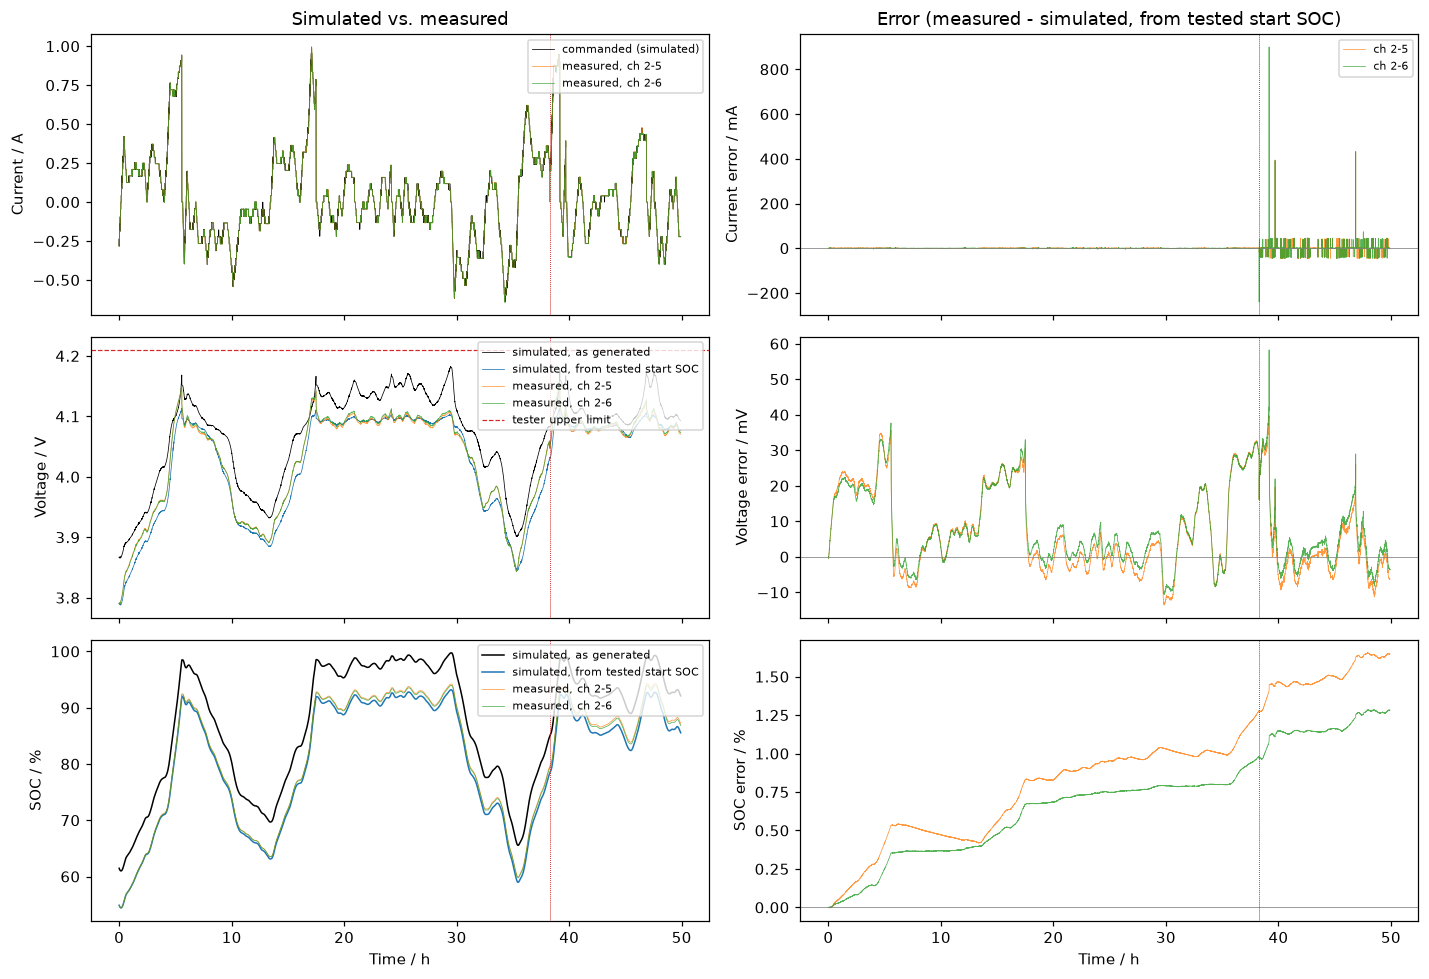

In [7]:
t_row_h = (np.arange(n) + 1) * dt / 3600   # end of each profile row
t_edge_h = np.arange(n + 1) * dt / 3600    # row edges (SOC)
colors = ["tab:orange", "tab:green", "tab:purple", "tab:brown"]
ERR_SIM = "from tested start SOC"

fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True)

# current
axes[0, 0].plot(t_row_h, sim_current, color="black", lw=0.5, label="commanded (simulated)")
for (label, c), color in zip(results.items(), colors):
    axes[0, 0].plot(c["t_h"], c["I_meas"], color=color, lw=0.5, alpha=0.8, label=f"measured, {label}")
    axes[0, 1].plot(c["t_h"], 1000 * (c["I_meas"] - c["I_sim"]), color=color, lw=0.5, alpha=0.8, label=label)
axes[0, 0].set_ylabel("Current / A")
axes[0, 1].set_ylabel("Current error / mA")

# voltage and SOC
for i, (key, ylabel, err_label, err_scale) in enumerate([
        ("V", "Voltage / V", "Voltage error / mV", 1000),
        ("soc", "SOC / %", "SOC error / %", 1)], start=1):
    for name, (v, soc_edges, sim_color) in SIMS.items():
        if key == "V":
            axes[i, 0].plot(t_row_h, v, color=sim_color, lw=0.5, label=f"simulated, {name}")
        else:
            axes[i, 0].plot(t_edge_h, soc_edges, color=sim_color, lw=1.0, label=f"simulated, {name}")
    for (label, c), color in zip(results.items(), colors):
        axes[i, 0].plot(c["t_h"], c[f"{key}_meas"], color=color, lw=0.5, alpha=0.8,
                        label=f"measured, {label}")
        axes[i, 1].plot(c["t_h"], err_scale * (c[f"{key}_meas"] - c[f"{key}_sim [{ERR_SIM}]"]),
                        color=color, lw=0.5, alpha=0.8, label=label)
    axes[i, 0].set_ylabel(ylabel)
    axes[i, 1].set_ylabel(err_label)

for ax in axes[:, 1]:
    ax.axhline(0, color="0.5", lw=0.5)
axes[1, 0].axhline(V_UPPER_LIMIT, color="tab:red", lw=0.8, ls="--", label="tester upper limit")
for ax in axes.flat:
    for t_out in outages["at step time / h"].unique():
        ax.axvline(t_out, color="tab:red", lw=0.5, ls=":")
for ax in axes[:, 0]:
    ax.legend(loc="upper right", fontsize=7)
axes[0, 1].legend(loc="upper right", fontsize=7)
axes[0, 0].set_title("Simulated vs. measured")
axes[0, 1].set_title(f"Error (measured - simulated, {ERR_SIM})")
axes[-1, 0].set_xlabel("Time / h")
axes[-1, 1].set_xlabel("Time / h")
plt.tight_layout()
plt.show()

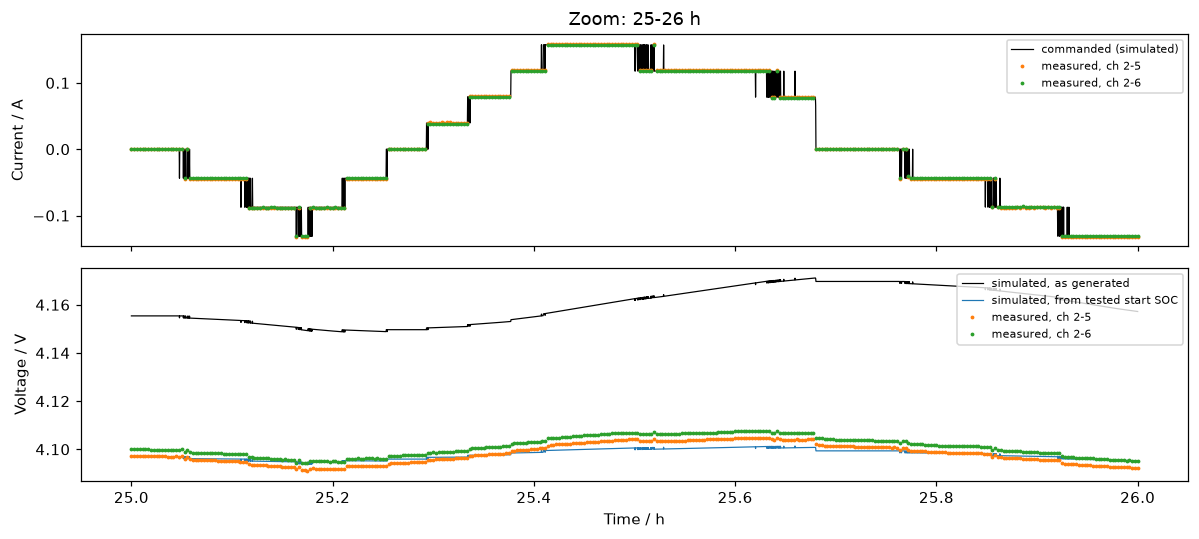

In [8]:
# Zoom on one hour, to see how well the 1 s dynamics are followed
ZOOM_START_H, ZOOM_LEN_H = 25.0, 1.0  # middle of the profile

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
zs = (t_row_h >= ZOOM_START_H) & (t_row_h <= ZOOM_START_H + ZOOM_LEN_H)
axes[0].plot(t_row_h[zs], sim_current[zs], color="black", lw=0.8, label="commanded (simulated)")
for name, (v, _, sim_color) in SIMS.items():
    axes[1].plot(t_row_h[zs], v[zs], color=sim_color, lw=0.8, label=f"simulated, {name}")
for (label, c), color in zip(results.items(), colors):
    zm = c["t_h"].between(ZOOM_START_H, ZOOM_START_H + ZOOM_LEN_H)
    axes[0].plot(c["t_h"][zm], c["I_meas"][zm], ".", ms=3, color=color, label=f"measured, {label}")
    axes[1].plot(c["t_h"][zm], c["V_meas"][zm], ".", ms=3, color=color, label=f"measured, {label}")
axes[0].set_ylabel("Current / A")
axes[1].set_ylabel("Voltage / V")
axes[1].set_xlabel("Time / h")
axes[0].set_title(f"Zoom: {ZOOM_START_H:g}-{ZOOM_START_H + ZOOM_LEN_H:g} h")
axes[0].legend(loc="upper right", fontsize=7)
axes[1].legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

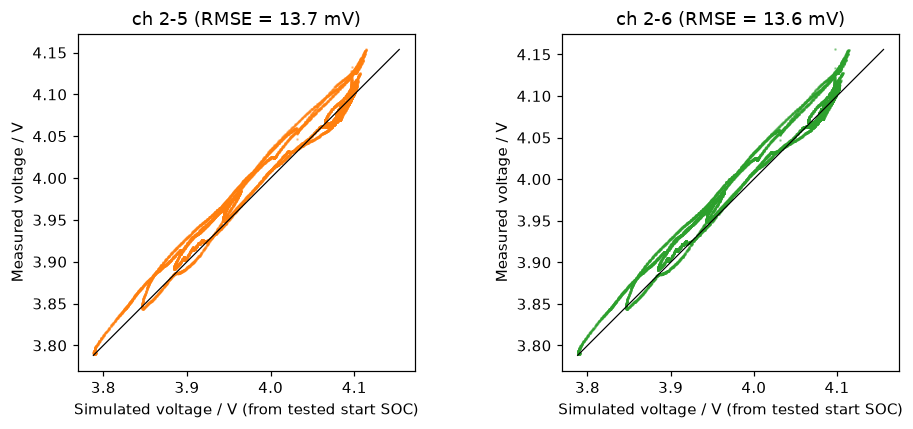

In [9]:
# Voltage parity: points on the diagonal mean the OCV+R0 model reproduces the cell
fig, axes = plt.subplots(1, len(results), figsize=(4.5 * len(results), 4), squeeze=False)
for ax, (label, c), color in zip(axes[0], results.items(), colors):
    v_sim = c[f"V_sim [{ERR_SIM}]"]
    ax.plot(v_sim, c["V_meas"], ".", ms=1.5, color=color, alpha=0.4)
    lims = [min(v_sim.min(), c["V_meas"].min()), max(v_sim.max(), c["V_meas"].max())]
    ax.plot(lims, lims, color="black", lw=0.8)
    ax.set_xlabel(f"Simulated voltage / V ({ERR_SIM})")
    ax.set_ylabel("Measured voltage / V")
    ax.set_title(f"{label} (RMSE = {1000 * rmse(c['V_meas'], v_sim):.1f} mV)")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 6. Profile tracking around the outage

In [10]:
# Current tracking before vs. after the outage
rows = []
for label, c in results.items():
    t_out = outages.loc[outages["cell"] == label, "at step time / h"]
    if t_out.empty:
        continue
    t_out = t_out.iloc[0]
    for part, m in [("before outage", c["t_h"] < t_out), ("after outage", c["t_h"] > t_out + 0.01)]:
        rows.append({
            "cell": label, "part": part,
            "current RMSE / mA": 1000 * rmse(c["I_meas"][m], c["I_sim"][m]),
            "current correlation": np.corrcoef(c["I_meas"][m], c["I_sim"][m])[0, 1],
        })
pd.DataFrame(rows).round(4)

,cell,part,current RMSE / mA,current correlation
0,ch 2-5,before outage,1.2050,1.0000
1,ch 2-5,after outage,13.7894,0.9989
2,ch 2-6,before outage,0.5163,1.0000
3,ch 2-6,after outage,19.6633,0.9977


The error jumps after the outage. Shifting the commanded profile in time shows
why: after resuming, the tester runs the profile a few seconds behind its step
clock. That moves every current change by those few seconds, but the profile
itself is unchanged.

In [11]:
SHIFTS = np.arange(-15, 16)  # s; negative = tester behind the step clock

rows = []
for label, meas in measured.items():
    t_out = outages.loc[outages["cell"] == label, "at step time / h"]
    if t_out.empty:
        continue
    t_s = meas["t_s"].to_numpy()
    for part, m in [("before outage", (t_s > 0) & (t_s < t_out.iloc[0] * 3600)),
                    ("after outage", t_s > t_out.iloc[0] * 3600 + 60)]:
        base_row = np.ceil(t_s[m] / dt).astype(int) - 1
        err = [1000 * rmse(meas["current_A"].to_numpy()[m],
                           sim_current[np.clip(base_row + sh // dt, 0, n - 1)]) for sh in SHIFTS]
        k = int(np.argmin(err))
        rows.append({"cell": label, "part": part, "best shift / s": SHIFTS[k],
                     "current RMSE at best shift / mA": err[k],
                     "current RMSE unshifted / mA": err[list(SHIFTS).index(0)]})
pd.DataFrame(rows).round(2)

,cell,part,best shift / s,current RMSE at best shift / mA,current RMSE unshifted / mA
0,ch 2-5,before outage,0,1.20,1.20
1,ch 2-5,after outage,-7,1.21,13.79
2,ch 2-6,before outage,0,0.52,0.52
3,ch 2-6,after outage,-7,2.42,19.67


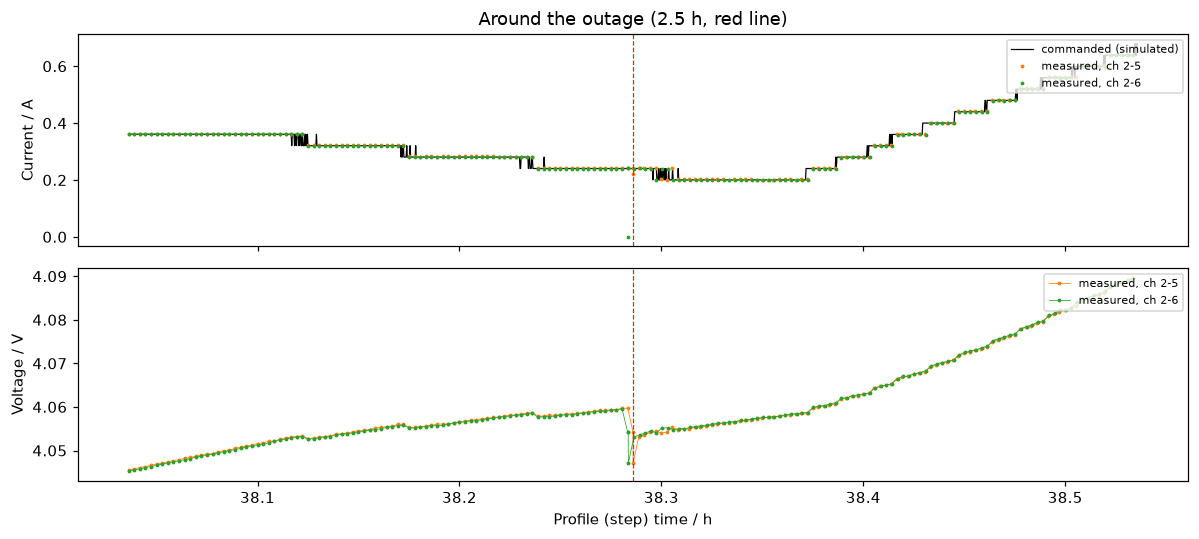

In [12]:
# Zoom on the outage (profile time): the step clock does not advance while the
# tester is down, so the trace continues where it stopped
t_out = outages["at step time / h"].iloc[0]
Z0, Z1 = t_out - 0.25, t_out + 0.25

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
zs = (t_row_h >= Z0) & (t_row_h <= Z1)
axes[0].plot(t_row_h[zs], sim_current[zs], color="black", lw=0.8, label="commanded (simulated)")
for (label, c), color in zip(results.items(), ["tab:orange", "tab:green"]):
    zm = c["t_h"].between(Z0, Z1)
    axes[0].plot(c["t_h"][zm], c["I_meas"][zm], ".", ms=3, color=color, label=f"measured, {label}")
    axes[1].plot(c["t_h"][zm], c["V_meas"][zm], ".-", ms=3, lw=0.5, color=color, label=f"measured, {label}")
for ax in axes:
    ax.axvline(t_out, color="tab:red", lw=0.8, ls="--")
axes[0].set_ylabel("Current / A")
axes[1].set_ylabel("Voltage / V")
axes[1].set_xlabel("Profile (step) time / h")
axes[0].set_title(f"Around the outage ({outages['duration / h'].iloc[0]:.1f} h, red line)")
axes[0].legend(loc="upper right", fontsize=7)
axes[1].legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

## 7. Findings (assessed 2026-11-10)

**First attempt, test 2818580853 (2-4 Nov 2026), failed.** Preconditioned to
61.5 % SOC (CC discharge of 1.768 Ah after CCCV), as `DEV_demo_PS.ipynb`
suggested. Both channels hit the 4.21 V upper limit at 39.2 h of the 49.9 h
profile. The tester followed the profile exactly; the cause was the SOC window:

- the profile nets up to **+1.80 Ah** above its start (~39 % of 4.589 Ah), so
  from 61.5 % it reaches ~100.6 % SOC when every Ah is counted;
- the notebook did not flag it because `eta_coulomb_ef = 0.99` hides ~1.3 % SOC
  on charge, and the OCV+R0 model underestimates the voltage near full charge
  by up to ~40 mV (no RC polarisation).

**Second attempt, test 2818580854 (4-6 Nov 2026), completed.** Same profile
file, preconditioned to ~55 % SOC (CC discharge of 2.07 Ah after CCCV):

- the full 49.9 h ran on both channels; SOC stayed within ~54.5-94.5 %, the
  voltage peaked at 4.154 V (ch 2-5) / 4.156 V (ch 2-6), ~55 mV below the limit;
- current tracking before the outage: RMSE 1.2 / 0.5 mA; net charge
  1.482 / 1.465 Ah vs. 1.467 Ah commanded; temperature 24.6-25.5 degC;
- OCV+R0 model from the tested start SOC: voltage RMSE ~14 mV, max error
  40-58 mV (largest near high SOC under charge), SOC RMSE 0.8-1.0 %;
- **power outage** on 6 Nov 09:34-12:03 (~2.5 h) at 38.3 h of profile time,
  ~80 % SOC: the tester paused the step clock, the cell sat at open circuit
  (relaxed 4.060 -> 4.047 V) and the profile resumed where it stopped. After
  resuming, the profile runs **~7 s behind the step clock** on both channels
  (section 6): with that shift the current error is back at 1-2 mA, so at most
  ~7 s of profile (~2 mAh) were repeated or not counted. The net effect is an extra ~2.5 h
  rest at ~80 % SOC, negligible against ~50 h of cycling. When comparing at
  1 s resolution after 38.3 h, shift the profile by 7 s;
- the profile is net-charging, so the cell ended at ~87 % SOC (4.077 V at rest).
  To repeat it, re-precondition to ~55 % SOC before each repetition.